# Fields of a sphere in a plane wave

This notebook computes the fields near a sphere in a plane wave: the electric and the magnetic fields in optics, and the pressure and the velocity in acoustics.
The fields are the multipole series with the amplitudes from `mielib`, in the conventions of the [theory note](https://github.com/toftul/mielib/blob/main/docs/theory/mielib_theory.pdf).
The positions are in units of the radius $a$.
The figures use the style file `phys-plots.mplstyle` and the helpers in `figure_style.py`, which are next to this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sp

from mielib import acoustics, coordinates, optics, special, vsh
from figure_style import use_paper_style, figure, letter, edges, signed_map

use_paper_style()

PosixPath('/home/ivan/Documents/GitHub/mielib/examples/phys-plots.mplstyle')

## Optics

The sphere of `cross_sections.ipynb`: the radius $a = 100$ nm and the permittivity $\varepsilon_p = 16 + 0.3i$ in vacuum.
The wavelength is at the maximum of the magnetic dipole scattering, row $j = 1$ of `q.sca_m`.

In [2]:
nm = 1e-9
a = 100 * nm
eps_p, mu_p = 16 + 0.3j, 1
eps_h, mu_h = 1, 1
eps_rel, mu_rel = eps_p / eps_h, mu_p / mu_h

wavelength = np.linspace(500, 1100, 1201) * nm          # in vacuum
k = np.sqrt(eps_h * mu_h) * 2 * np.pi / wavelength     # in the host
q = optics.cross_sections(k, a, eps_rel, mu_rel)

i = np.argmax(q.sca_m[1])
ka = k[i] * a
print(f'wavelength = {wavelength[i] / nm:.1f} nm, ka = {ka:.3f}')

wavelength = 830.5 nm, ka = 0.757


The normalized fields $\mathbf{e} = \sqrt{\varepsilon}\mathbf{E}/\mathcal{A}$ and $\mathbf{h} = \sqrt{\mu}\mathbf{H}/\mathcal{A}$ are
$$
\mathbf{e} = \sum_{jm}\left(A_{jm}\mathbf{N}_{jm} + B_{jm}\mathbf{M}_{jm}\right), \qquad
\mathbf{h} = -i\sum_{jm}\left(B_{jm}\mathbf{N}_{jm} + A_{jm}\mathbf{M}_{jm}\right).
$$
The incident wave $\mathbf{e} = \hat{\mathbf{x}}\, e^{ikz}$, $\mathbf{h} = \hat{\mathbf{y}}\, e^{ikz}$ has $z_j = j_j(kr)$ and
$A_{\pm1, j} = \pm\eta_j/2$, $B_{\pm1, j} = \eta_j/2$ with $\eta_j = i^{j+1}\sqrt{4\pi(2j+1)/[j(j+1)]}$.
The scattered field has $z_j = h^{(1)}_j(kr)$ and the amplitudes $T^e_j A_{jm}$ and $T^m_j B_{jm}$ from `optics.tmatrix`.
Inside, the same series with $z_j = j_j(k_p r)$ and the amplitudes from `optics.internal_amplitudes` is $\sqrt{\varepsilon_p}\mathbf{E}/\mathcal{A}$ and $\sqrt{\mu_p}\mathbf{H}/\mathcal{A}$.

The incident $\mathbf{E}$ and $\mathbf{H}$ have the amplitudes $E_0$ and $H_0$.
Outside, $\mathbf{E}/E_0 = \mathbf{e}$ and $\mathbf{H}/H_0 = \mathbf{h}$.
Inside, $\mathbf{E}/E_0$ and $\mathbf{H}/H_0$ are the internal series divided by $\sqrt{\varepsilon_{\rm rel}}$ and $\sqrt{\mu_{\rm rel}}$.
Outside, the code adds the incident wave in closed form, so the series has only the scattered terms.
The series stop at $j_{\max}$ from `special.wiscombe_jmax(ka)`.

In [3]:
def eh_sum(rho, theta, phi, amplitudes, superscript):
    # e = Σ (A N + B M) and h = -i Σ (B N + A M) for a list of (j, m, A, B), in Cartesian components
    e, h = 0, 0
    for j, m, A, B in amplitudes:
        N = vsh.N(j, m, rho, theta, phi, superscript=superscript)
        M = vsh.M(j, m, rho, theta, phi, superscript=superscript)
        e = e + A * N + B * M
        h = h - 1j * (B * N + A * M)
    return coordinates.vector_sph2cart(e, theta, phi), coordinates.vector_sph2cart(h, theta, phi)


def optical_fields(x, y, z, ka, eps_rel, mu_rel):
    # E/E0 and H/H0 in Cartesian components for the wave E0 x exp(ikz), at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    inside, outside = r < 1, r >= 1
    sqrt_eps, sqrt_mu = np.sqrt(eps_rel + 0j), np.sqrt(mu_rel + 0j)

    scattered, internal = [], []
    for j in range(1, special.wiscombe_jmax(ka) + 1):
        eta = 1j**(j + 1) * np.sqrt(4 * np.pi * (2 * j + 1) / (j * (j + 1)))
        te, tm = optics.tmatrix(j, ka, eps_rel, mu_rel)
        a_in, b_in = optics.internal_amplitudes(j, ka, eps_rel, mu_rel)
        for m in (1, -1):
            A, B = m * eta / 2, eta / 2
            scattered.append((j, m, te * A, tm * B))
            internal.append((j, m, a_in * A, b_in * B))

    E = np.zeros((3,) + r.shape, dtype=complex)
    H = np.zeros((3,) + r.shape, dtype=complex)
    # h_j(kr) diverges at r = 0, so each series is computed only in its own region
    E[:, outside], H[:, outside] = eh_sum(ka * r[outside], theta[outside], phi[outside], scattered, superscript=3)
    E[0, outside] += np.exp(1j * ka * z[outside])
    H[1, outside] += np.exp(1j * ka * z[outside])
    e, h = eh_sum(sqrt_eps * sqrt_mu * ka * r[inside], theta[inside], phi[inside], internal, superscript=1)
    E[:, inside], H[:, inside] = e / sqrt_eps, h / sqrt_mu
    return E, H

**Check.** The tangential components of $\mathbf{E}$ and $\mathbf{H}$ and the normal components of $\varepsilon\mathbf{E}$ and $\mu\mathbf{H}$ are continuous at $r = a$.
The jumps between the points just inside and just outside the sphere are as small as the omitted terms $j > j_{\max}$.

In [4]:
theta, phi = np.meshgrid(np.linspace(0.1, 3.0, 7), np.linspace(0.2, 6.0, 7))
sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    E, H = optical_fields(*coordinates.sph2cart(r, theta, phi), ka, eps_rel, mu_rel)
    sides.append((coordinates.vector_cart2sph(E, theta, phi), coordinates.vector_cart2sph(H, theta, phi)))
(E_in, H_in), (E_out, H_out) = sides

print(f'jmax = {special.wiscombe_jmax(ka)}, the largest jump in')
print(f'  tangential E:  {np.max(np.abs(E_in[1:] - E_out[1:])):.1e}')
print(f'  tangential H:  {np.max(np.abs(H_in[1:] - H_out[1:])):.1e}')
print(f'  normal eps E:  {np.max(np.abs(eps_rel * E_in[0] - E_out[0])):.1e}')
print(f'  normal mu H:   {np.max(np.abs(mu_rel * H_in[0] - H_out[0])):.1e}')

jmax = 6, the largest jump in
  tangential E:  4.8e-06
  tangential H:  5.1e-06
  normal eps E:  4.7e-06
  normal mu H:   4.4e-06


**Figure 1.** The fields at the magnetic dipole resonance.
(A) The electric field $|\mathbf{E}|/E_0$ in the plane $y = 0$.
(B) The magnetic field $|\mathbf{H}|/H_0$ in the plane $x = 0$.
The incident $\mathbf{E}$ is along $x$, and the mirror symmetries of the problem keep $\mathbf{E}$ in the plane $y = 0$ and $\mathbf{H}$ in the plane $x = 0$.
The lines show the instantaneous fields $\mathrm{Re}[\mathbf{E}\, e^{-i\omega t}]$ and $\mathrm{Re}[\mathbf{H}\, e^{-i\omega t}]$ at $\omega t = \pi/4$.
The dashed circle is the surface of the sphere.
The electric field circulates in a loop inside the sphere, and the magnetic field goes through the loop along $y$, as for a magnetic dipole along $y$.
At the centre, $|\mathbf{H}| \approx 20 H_0$.

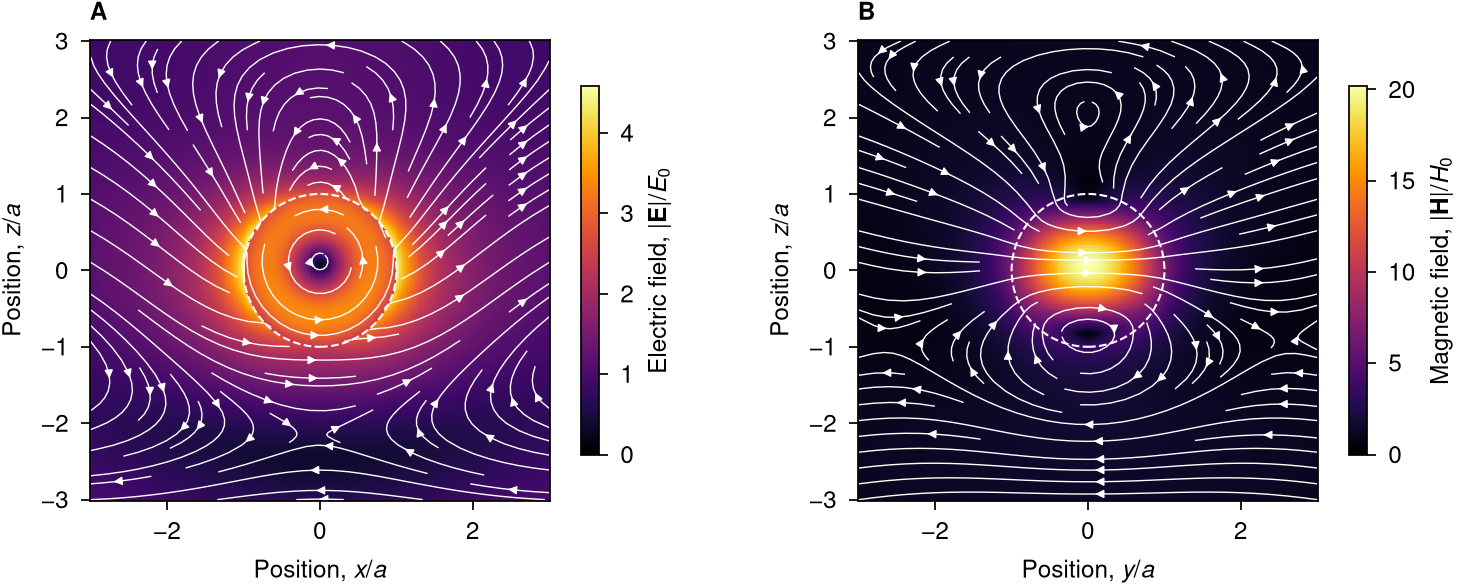

In [5]:
u = np.linspace(-3, 3, 241)                     # position in units of a
U, V = np.meshgrid(u, u)
E, _ = optical_fields(U, 0, V, ka, eps_rel, mu_rel)
_, H = optical_fields(0, U, V, ka, eps_rel, mu_rel)
wt = np.pi / 4


def vector_map(ax, u, F, i, wt, label):
    # |F| and the lines of Re[F exp(-iωt)] in a plane; F[i] is along the horizontal axis and F[2] along z
    magnitude = np.sqrt(np.sum(np.abs(F)**2, axis=0))
    mesh = ax.pcolormesh(edges(u), edges(u), magnitude, vmin=0, shading='flat', rasterized=True)
    snapshot = np.real(F * np.exp(-1j * wt))
    ax.streamplot(u, u, snapshot[i], snapshot[2], color='w', linewidth=0.4, arrowsize=0.5)
    bar = ax.figure.colorbar(mesh, ax=ax, shrink=0.8, label=label)
    bar.outline.set_linewidth(0.5)


fig, (ax1, ax2) = figure('double', cols=2)
vector_map(ax1, u, E, 0, wt, r'Electric field, $|\mathbf{E}|/E_0$')
vector_map(ax2, u, H, 1, wt, r'Magnetic field, $|\mathbf{H}|/H_0$')

for ax, horizontal, name in zip([ax1, ax2], 'xy', 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='w', ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(rf'Position, ${horizontal}/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()

## Acoustics

The fluid sphere of `cross_sections.ipynb`, with the density $\rho_{\rm rel} = 3 + 0.1i$ and the compressibility $\beta_{\rm rel} = 2$ relative to the host.
The size parameter is at the maximum of the dipole scattering, row $j = 1$ of `q.sca_j`.

In [6]:
rho_rel, beta_rel = 3 + 0.1j, 2

a = 1
k = np.linspace(0.01, 5, 2000)
q = acoustics.cross_sections(k, a, rho_rel, beta_rel)

ka = k[np.argmax(q.sca_j[1])] * a
print(f'ka = {ka:.3f}')

ka = 1.528


The pressure and the velocity $\mathbf{v} = \nabla p/(i\omega\rho)$ are
$$
\frac{p}{p_0} = \sum_{j} C_j\, z_j\, Y_{j0}, \qquad
\frac{\rho c\, \mathbf{v}}{p_0} = -i\sum_{j} C_j\, \mathbf{L}_{j0},
$$
with $\mathbf{L}_{j0} = k^{-1}\nabla(z_j Y_{j0})$.
The incident wave $p = p_0 e^{ikz}$ has $z_j = j_j(kr)$ and $C_j = i^j\sqrt{4\pi(2j+1)}$.
The scattered pressure has $z_j = h^{(1)}_j(kr)$ and the amplitudes $T_j C_j$ from `acoustics.tmatrix`.
The internal pressure has $z_j = j_j(k_p r)$ and the amplitudes $c_j C_j$ from `acoustics.mie_c`.
Inside, $\rho_p$ replaces $\rho$ and $k_p$ replaces $k$ in $\mathbf{L}_{j0}$, so the velocity series has the factor $k_p/(k\rho_{\rm rel})$ with $k_p/k = \sqrt{\rho_{\rm rel}\beta_{\rm rel}}$.
Here $\rho$ and $c$ are the density and the sound speed of the host, so the incident wave has $\rho c|\mathbf{v}| = p_0$.

In [7]:
def pv_sum(rho, theta, phi, amplitudes, superscript):
    # p = Σ C z_j Y_j0 and ρc v = -i Σ C L_j0 for a list of (j, C), v in Cartesian components
    p, v = 0, 0
    for j, C in amplitudes:
        p = p + C * special.spherical_z(j, rho, superscript=superscript) * sp.sph_harm_y(j, 0, theta, phi)
        v = v - 1j * C * vsh.L(j, 0, rho, theta, phi, superscript=superscript)
    return p, coordinates.vector_sph2cart(v, theta, phi)


def acoustic_fields(x, y, z, ka, rho_rel, beta_rel):
    # p/p0 and ρc v/p0 in Cartesian components for the wave p0 exp(ikz), at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    inside, outside = r < 1, r >= 1
    n = np.sqrt(rho_rel + 0j) * np.sqrt(beta_rel + 0j)       # k_p / k

    scattered, internal = [], []
    for j in range(special.wiscombe_jmax(ka) + 1):
        C = 1j**j * np.sqrt(4 * np.pi * (2 * j + 1))
        scattered.append((j, acoustics.tmatrix(j, ka, rho_rel, beta_rel) * C))
        internal.append((j, acoustics.mie_c(j, ka, rho_rel, beta_rel) * C))

    p = np.zeros(r.shape, dtype=complex)
    v = np.zeros((3,) + r.shape, dtype=complex)
    # h_j(kr) diverges at r = 0, so each series is computed only in its own region
    p[outside], v[:, outside] = pv_sum(ka * r[outside], theta[outside], phi[outside], scattered, superscript=3)
    p[outside] += np.exp(1j * ka * z[outside])
    v[2, outside] += np.exp(1j * ka * z[outside])
    p[inside], v_in = pv_sum(n * ka * r[inside], theta[inside], phi[inside], internal, superscript=1)
    v[:, inside] = n / rho_rel * v_in
    return p, v

**Check.** The pressure and the normal velocity are continuous at $r = a$.

In [8]:
theta, phi = np.meshgrid(np.linspace(0.1, 3.0, 7), np.linspace(0.2, 6.0, 7))
sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    p, v = acoustic_fields(*coordinates.sph2cart(r, theta, phi), ka, rho_rel, beta_rel)
    sides.append((p, coordinates.vector_cart2sph(v, theta, phi)))
(p_in, v_in), (p_out, v_out) = sides

print(f'jmax = {special.wiscombe_jmax(ka)}, the largest jump in')
print(f'  pressure:         {np.max(np.abs(p_in - p_out)):.1e}')
print(f'  normal velocity:  {np.max(np.abs(v_in[0] - v_out[0])):.1e}')

jmax = 8, the largest jump in
  pressure:         9.8e-07
  normal velocity:  5.7e-06


**Figure 2.** The fields at the dipole resonance in the plane $y = 0$.
(A) The instantaneous pressure $\mathrm{Re}[p\, e^{-i\omega t}]/p_0$ at $\omega t = \pi/4$. The dotted lines are $p = 0$.
(B) The velocity $\rho c|\mathbf{v}|/p_0$, and the lines of $\mathrm{Re}[\mathbf{v}\, e^{-i\omega t}]$ at the same time.
The problem is symmetric about the $z$ axis, so $\mathbf{v}$ is in the plane.
The dashed circle is the surface of the sphere.
Inside the sphere the pressure has opposite signs near the top and the bottom, as for a dipole along $z$,
and the velocity is largest at the centre, $\rho c|\mathbf{v}| \approx 3 p_0$.

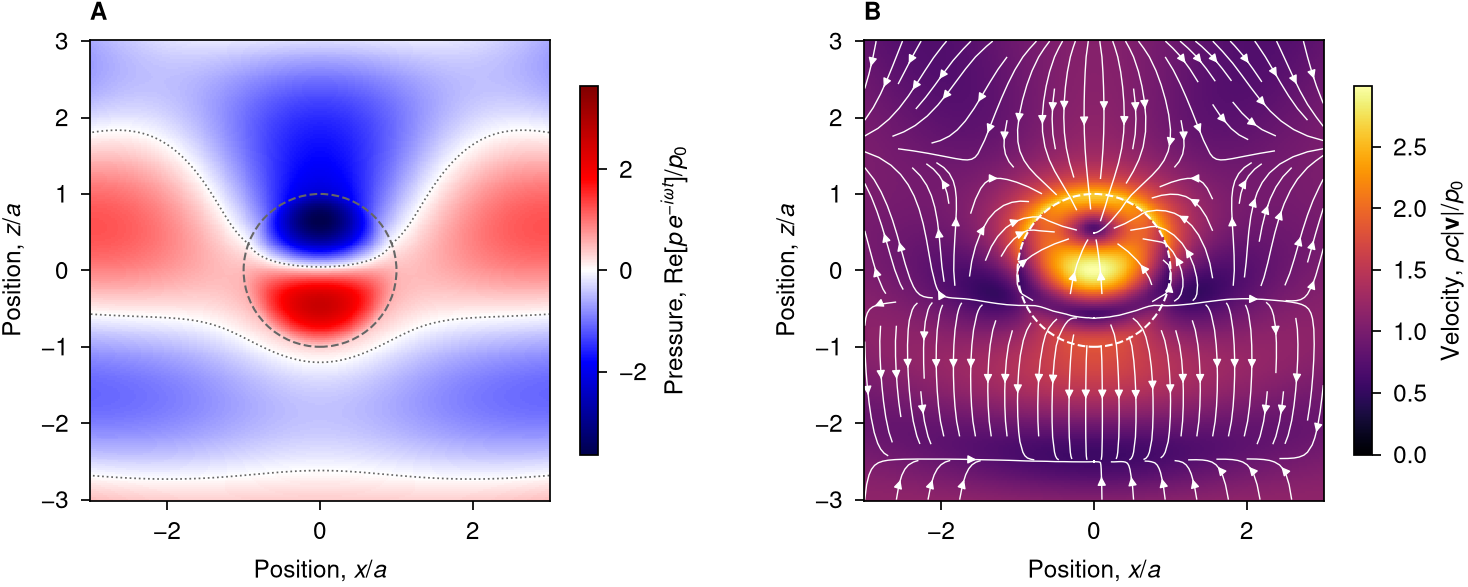

In [9]:
p, v = acoustic_fields(U, 0, V, ka, rho_rel, beta_rel)

fig, (ax1, ax2) = figure('double', cols=2)
mesh = signed_map(ax1, u, u, np.real(p * np.exp(-1j * wt)))
bar = fig.colorbar(mesh, ax=ax1, shrink=0.8, label=r'Pressure, $\mathrm{Re}[p\, e^{-i\omega t}]/p_0$')
bar.outline.set_linewidth(0.5)
vector_map(ax2, u, v, 0, wt, r'Velocity, $\rho c|\mathbf{v}|/p_0$')

for ax, color, name in zip([ax1, ax2], ['0.4', 'w'], 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=color, ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(r'Position, $x/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()